# Modul KKA: Adversarial Search

## Tujuan praktikum

Anda akan menelusuri minimax dan alpha-beta, membedakan nilai akhir permainan
dari fungsi evaluasi, serta mengukur pengaruh urutan langkah pada jumlah simpul
yang diperiksa. Contoh menggunakan permainan dua pemain, bergiliran,
deterministik, dan berinformasi sempurna.

## Persiapan praktikum

Lengkapi identitas berikut. Petunjuk menjalankan Jupyter dan Google Colab tersedia di README.

| Nama | NRP |
|---|---|
| | |

### Mengenali bagian yang harus diisi

Setiap bagian tugas diberi komentar **`# TODO [kode]`**, diikuti penanda
**`________("kode")`** pada posisi jawaban. Nomor pada komentar dan penanda
sama, misalnya U01.

- Ganti **seluruh pemanggilan** `________("U01")`, termasuk tanda kurung dan
  kodenya, dengan ekspresi atau perintah Python yang diminta pada komentar.
- Untuk tugas satu fungsi penuh, tulis implementasi di antara komentar
  `# __ MULAI JAWABAN __` dan `# __ AKHIR JAWABAN __`. Hapus baris penandanya.
- Kode di luar penanda sudah disediakan. Sel bertanda **PENGUJIAN** tidak perlu
  diubah; jalankan setelah fungsi latihan selesai diisi.

Contoh: jika diminta menghitung dua kali x, ubah `nilai = ________("X01")`
menjadi `nilai = 2 * x`.

Jalankan sel berurutan. Setelah mengubah fungsi, jalankan kembali sel definisi
dan sel pengujiannya. Pesan **BELUM DIISI** menyebut kode TODO yang masih kosong.
Jika `assert` gagal, periksa kembali jawaban Anda. Fungsi penanda di bawah
digunakan untuk menampilkan pesan tersebut dan tidak perlu diubah.

In [ ]:
from pathlib import Path
import sys
import random
import numpy as np

# Folder data/ harus berada satu tingkat dengan notebook.
module_root = next((p for p in (Path.cwd(), Path.cwd().parent)
                    if (p / 'data/experiments.py').is_file()), None)
if module_root is None:
    raise FileNotFoundError('Folder data/ tidak ditemukan. Ikuti petunjuk pada README.')
sys.path.insert(0, str(module_root.resolve()))
random.seed(42)
np.random.seed(42)

In [ ]:
# FUNGSI PENANDA LATIHAN — tidak perlu diubah.
def ________(kode):
    raise NotImplementedError(f"TODO [{kode}] belum diisi. Lihat komentar TODO dengan kode yang sama.")

## 1. Pendahuluan

Pada permainan dua pemain, akibat suatu langkah bergantung pada balasan lawan.
Adversarial search memilih langkah dengan memperhitungkan balasan tersebut.
Modul ini menggunakan minimax untuk menentukan nilai langkah dan alpha-beta
untuk mengurangi pencarian yang tidak memengaruhi keputusan.

## 2. Konsep Dasar

### 2.1 Permainan zero-sum

Pada permainan zero-sum, nilai untuk satu pemain merupakan kebalikan nilai
untuk pemain lain. Misalnya, jika X mendapat +1 karena menang, O mendapat −1.
Hasil seri bernilai 0 untuk keduanya. Tic-tac-toe digunakan sebagai contoh.

### 2.2 Komponen permainan

| Komponen | Arti |
|---|---|
| $S_0$ | Keadaan awal |
| `TO-MOVE(s)` | Pemain yang mendapat giliran |
| `ACTIONS(s)` | Langkah yang sah pada keadaan s |
| `RESULT(s, a)` | Keadaan setelah langkah a |
| `IS-TERMINAL(s)` | Apakah permainan telah selesai? |
| `UTILITY(s, p)` | Nilai hasil akhir untuk pemain p |

Pada contoh tic-tac-toe, utility dari sudut pandang X adalah +1 untuk kemenangan
X, −1 untuk kemenangan O, dan 0 untuk seri.

### 2.3 Pohon permainan

Akar pohon adalah keadaan saat ini. Sisi menyatakan langkah yang sah dan daun
pada penelusuran penuh menyatakan keadaan akhir permainan. Giliran bergantian
antara MAX dan MIN. Semua nilai ditulis dari sudut pandang MAX.

```text
           MAX
          /   \
        MIN   MIN
        / \   / \
       3   5 2   9
```

MIN memilih 3 pada cabang kiri dan 2 pada cabang kanan. MAX lalu memilih cabang
kiri dengan nilai 3.

## 3. Algoritma Minimax
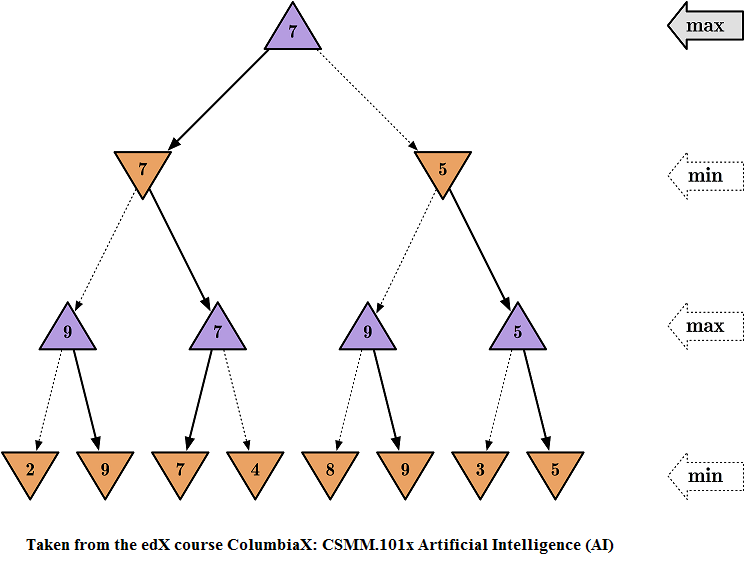

### 3.1 Cara kerja minimax

Minimax menghitung utility pada keadaan akhir, lalu meneruskan nilainya ke induk.
MAX mengambil nilai anak terbesar; MIN mengambil yang terkecil. MAX memilih
langkah dengan nilai tertinggi di akar, dengan asumsi lawan juga memilih
balasan terbaik baginya.

```text
MINIMAX(s) = UTILITY(s)                jika s terminal
           = max MINIMAX(RESULT(s,a))  jika giliran MAX
           = min MINIMAX(RESULT(s,a))  jika giliran MIN
```

Pada pohon berhingga, minimax memeriksa seluruh kemungkinan yang diperlukan
untuk menjamin hasil terhadap permainan optimal lawan. Dengan b sebagai jumlah
langkah maksimum dan m sebagai kedalaman pohon, waktunya $O(b^m)$ dan memori
penelusuran mendalamnya $O(bm)$.

### 3.2 Contoh perhitungan

A adalah MAX, B–D adalah MIN, dan E–J adalah MAX. Nilai anak E–J pada graf berikut
memberikan hasil:

| Simpul | Nilai minimax |
|---|---|
| E, F | 8, 6 |
| G, H | 8, 4 |
| I, J | 2, 5 |
| B = min(E, F) | 6 |
| C = min(G, H) | 4 |
| D = min(I, J) | 2 |
| A = max(B, C, D) | 6 |

Langkah terbaik dari A adalah menuju B.

### 3.3 Representasi graf

Dictionary `tree` menyimpan nama simpul sebagai key dan daftar anak sebagai
value. Nilai bilangan bulat pada daftar anak merupakan utility keadaan akhir.

In [ ]:
tree = {
    'A': ['B', 'C', 'D'],
    
    'B': ['E', 'F'],
    'C': ['G', 'H'],
    'D': ['I', 'J'],
    
    'E': [8, 5],
    'F': [6, -4],
    'G': [3, 8],
    'H': [4, -6],
    'I': [1, 2],
    'J': [5, 2]
}

### 3.4 Implementasi minimax

Kembalikan utility jika simpul berupa daun. Selain itu, telusuri anak secara
rekursif dan ambil maksimum atau minimum sesuai giliran pemain.

In [ ]:
def minimax(node, maximizingPlayer):

    # Base case
    if node not in tree:
        return node

    if maximizingPlayer:
        bestValue = float('-inf')
        for child in tree[node]:
            value = minimax(child, False)
            bestValue = max(bestValue, value)
        return bestValue

    else:
        bestValue = float('inf')
        for child in tree[node]:
            value = minimax(child, True)
            bestValue = min(bestValue, value)
        return bestValue

In [ ]:
def find_best_move(node):
    bestValue = float('-inf')
    bestMove = None

    for child in tree[node]:
        value = minimax(child, False)
        if value > bestValue:
            bestValue = value
            bestMove = child
    return bestMove, bestValue

In [ ]:
move, value = find_best_move('A')

print("Langkah terbaik:", move)
print("Nilai:", value)

### 3.5 Urutan perhitungan

Jalankan `minimax_trace` untuk melihat urutan kunjungan dan nilai yang
dikembalikan ke setiap induk.

In [ ]:
def minimax_trace(node, maximizingPlayer, indent=""):

    if node not in tree:
        print(f"{indent}{node}")
        return node
    print(f"{indent}{node} ({'MAX' if maximizingPlayer else 'MIN'})")

    if maximizingPlayer:
        bestValue = float('-inf')
        for child in tree[node]:
            value = minimax_trace(child, False, indent + "  ")
            bestValue = max(bestValue, value)
        print(f"{indent}-> pilih {bestValue}")
        return bestValue

    else:
        bestValue = float('inf')
        for child in tree[node]:
            value = minimax_trace(child, True, indent + "  ")
            bestValue = min(bestValue, value)

        print(f"{indent}-> pilih {bestValue}")
        return bestValue

In [ ]:
result = minimax_trace('A', maximizingPlayer=True)
print("\nNilai optimal:", result)

## 4. Alpha-Beta Pruning

### 4.1 Pemangkasan cabang

Alpha-beta menghentikan penelusuran cabang yang tidak dapat memperbaiki pilihan
pemain pada simpul sebelumnya. Nilai minimax di akar tetap sama, tetapi sebagian
simpul tidak perlu dikunjungi.

### 4.2 Batas alpha dan beta

| Batas | Arti |
|---|---|
| Alpha, $\alpha$ | Batas bawah nilai yang dapat dipertahankan MAX dari pilihan yang sudah diperiksa |
| Beta, $\beta$ | Batas atas nilai yang dapat dipertahankan MIN dari pilihan yang sudah diperiksa |

Pada simpul MAX, alpha diperbarui ketika nilai yang lebih besar ditemukan.
Pada simpul MIN, beta diperbarui ketika nilai yang lebih kecil ditemukan.
Sisa anak dapat dipangkas ketika $\beta\le\alpha$.

Urutan langkah memengaruhi jumlah pemangkasan. Pada urutan ideal, waktu dapat
mendekati $O(b^{m/2})$; pada kasus terburuk tetap $O(b^m)$.

### 4.3 Contoh pemangkasan

Gunakan pohon yang sama dengan contoh minimax. Setelah B selesai dihitung,
alpha di A bernilai 6. Pada D, anak I mengembalikan 2 sehingga beta D menjadi 2.
Karena beta D ≤ alpha A, J tidak perlu ditelusuri: MAX sudah memiliki pilihan
bernilai 6, sedangkan MIN pada D dapat memilih nilai 2.

Nilai akar tetap 6. Jalankan penelusuran kode untuk melihat batas pada simpul lainnya.

### 4.4 Implementasi alpha-beta

Bawa alpha dan beta ke pemanggilan rekursif. Setelah satu anak selesai dihitung,
perbarui batas yang sesuai dan periksa kondisi pemangkasan.

In [ ]:
def alphabeta(node, alpha, beta, maximizingPlayer):

    # Base case
    if node not in tree:
        return node

    if maximizingPlayer:
        bestValue = float('-inf')
        for child in tree[node]:
            value = alphabeta(child, alpha, beta, False)
            bestValue = max(bestValue, value)
            alpha = max(alpha, bestValue)
            # Pruning
            if beta <= alpha:
                break
        return bestValue

    else:
        bestValue = float('inf')
        for child in tree[node]:
            value = alphabeta(child, alpha, beta, True)
            bestValue = min(bestValue, value)
            beta = min(beta, bestValue)
            # Pruning
            if beta <= alpha:
                break
        return bestValue

In [ ]:
def find_best_move_ab(node):

    bestValue = float('-inf')
    bestMove = None

    alpha = float('-inf')
    beta = float('inf')

    for child in tree[node]:
        value = alphabeta(child, alpha, beta, False)

        if value > bestValue:
            bestValue = value
            bestMove = child

        alpha = max(alpha, bestValue)

    return bestMove, bestValue

In [ ]:
print("Minimax:", minimax('A', True))

print("Alpha-Beta:", alphabeta('A', float('-inf'), float('inf'), True))
print('Langkah terbaik alpha-beta:', find_best_move_ab('A'))
assert find_best_move('A') == find_best_move_ab('A') == ('B', 6)
print('LULUS minimax/alpha-beta tree')

### 4.5 Urutan perhitungan alpha-beta

In [ ]:
def alphabeta_trace(node, alpha, beta, maximizingPlayer, indent=""):

    if node not in tree:
        print(f"{indent}{node}")
        return node
    print(f"{indent}{node} ({'MAX' if maximizingPlayer else 'MIN'}) [α={alpha}, β={beta}]")

    if maximizingPlayer:
        bestValue = float('-inf')
        for child in tree[node]:
            value = alphabeta_trace(child, alpha, beta, False, indent + "  ")
            bestValue = max(bestValue, value)
            alpha = max(alpha, bestValue)
            if beta <= alpha:
                print(f"{indent} PANGKAS (β ≤ α)")
                break
        print(f"{indent}-> pilih {bestValue}")
        return bestValue

    else:
        bestValue = float('inf')
        for child in tree[node]:
            value = alphabeta_trace(child, alpha, beta, True, indent + "  ")
            bestValue = min(bestValue, value)
            beta = min(beta, bestValue)
            if beta <= alpha:
                print(f"{indent} PANGKAS (β ≤ α)")
                break
        print(f"{indent}-> pilih {bestValue}")
        return bestValue

In [ ]:
result = alphabeta_trace('A', float('-inf'), float('inf'), True)
print("\nNilai optimal:", result)

### 4.6 Menghitung simpul yang dikunjungi

Tambahkan satu pada penghitung setiap kali fungsi rekursif dipanggil, termasuk
pada akar dan daun. Gunakan pohon serta urutan anak yang sama untuk kedua metode.

In [ ]:
# Versi Minimax dengan penghitung node untuk perbandingan
node_count_minimax = 0

def minimax_counted(tree, node, is_max):
    global node_count_minimax
    node_count_minimax += 1
    
    if node not in tree or isinstance(tree[node], int):
        return node if node not in tree else tree[node]
    children = tree[node]
    
    if is_max:
        best_score = float('-inf')
        for child in children:
            score = minimax_counted(tree, child, False)
            best_score = max(best_score, score)
        return best_score
    else:
        best_score = float('inf')
        for child in children:
            score = minimax_counted(tree, child, True)
            best_score = min(best_score, score)
        return best_score

In [ ]:
# Versi Alpha-Beta dengan penghitung node untuk perbandingan
node_count_ab = 0

def alpha_beta_counted(tree, node, is_max, alpha, beta):
    global node_count_ab
    node_count_ab += 1
    
    if node not in tree or isinstance(tree[node], int):
        return node if node not in tree else tree[node]
    children = tree[node]
    
    if is_max:
        value = float('-inf')
        for child in children:
            value = max(value, alpha_beta_counted(tree, child, False, alpha, beta))
            alpha = max(alpha, value)
            if beta <= alpha:
                break
        return value
    else:
        value = float('inf')
        for child in children:
            value = min(value, alpha_beta_counted(tree, child, True, alpha, beta))
            beta = min(beta, value)
            if beta <= alpha:
                break
        return value

### 4.7 Membandingkan hasil

Jalankan kedua metode pada pohon yang sama. Periksa kesamaan nilai akar dan
bandingkan jumlah kunjungannya.

In [ ]:
# Pohon yang sama dengan contoh minimax

study_tree = {
    'A': ['B', 'C', 'D'],
    
    'B': ['E', 'F'],
    'C': ['G', 'H'],
    'D': ['I', 'J'],
    
    'E': [8, 5],
    'F': [6, -4],
    'G': [3, 8],
    'H': [4, -6],
    'I': [1, 2],
    'J': [5, 2]
}

# Reset counter
node_count_minimax = 0
node_count_ab = 0

# Jalankan Minimax biasa pada game tree yang sama
nilai_minimax = minimax_counted(study_tree, 'A', True)

# Jalankan Alpha-Beta Pruning pada game tree yang sama
nilai_ab = alpha_beta_counted(study_tree, 'A', True, float('-inf'), float('inf'))

print("Jumlah simpul yang dikunjungi:")
print(f"  Minimax biasa       : {node_count_minimax} node")
print(f"  Alpha-Beta Pruning  : {node_count_ab} node")
print(f"  Penghematan         : {node_count_minimax - node_count_ab} node ({((node_count_minimax - node_count_ab)/node_count_minimax * 100):.1f}%)")
print(f"  Nilai Minimax       : {nilai_minimax}")
print(f"  Nilai Alpha-Beta    : {nilai_ab}")
print("  Hasil sama          :", nilai_minimax == nilai_ab)

## 5. Ringkasan

| Aspek | Minimax | Alpha-beta |
|---|---|---|
| Nilai akar pada penelusuran penuh | Nilai minimax | Sama dengan minimax |
| Cabang yang ditelusuri | Semua anak sampai terminal | Anak yang masih dapat memengaruhi keputusan |
| Waktu kasus terburuk | $O(b^m)$ | $O(b^m)$ |
| Waktu dengan urutan ideal | $O(b^m)$ | Mendekati $O(b^{m/2})$ |
| Informasi tambahan | Giliran pemain | Giliran pemain, alpha, dan beta |

## 6. Latihan dasar

### Tic-tac-toe dengan minimax dan alpha-beta

Lengkapi `minimax`, `find_best_move`, dan `alphabeta`. X bertindak sebagai MAX
dan O sebagai MIN. Sel kosong ditulis sebagai satu spasi (`' '`). Gunakan
utility +1 untuk kemenangan X, −1 untuk kemenangan O, dan 0 untuk seri.

Pertanyaan:
1. Mengapa X perlu menutup ancaman O pada kolom tengah di papan uji?
2. Mengapa pemangkasan tidak mengubah nilai minimax?
3. Dapatkah urutan langkah mengubah jumlah kunjungan tanpa mengubah nilai akar?

#### Konstanta permainan

In [ ]:
EMPTY = ' '
MAX = 'X'
MIN = 'O'

#### Fungsi pendukung

In [ ]:
import copy

def get_moves(board):
    return [(r, c) for r in range(3) for c in range(3) if board[r][c] == EMPTY]

def apply_move(board, move, player):
    new_board = copy.deepcopy(board)
    r, c = move
    new_board[r][c] = player
    return new_board

def check_winner(board):
    lines = []
    lines.extend(board)

    for c in range(3):
        lines.append([board[r][c] for r in range(3)])

    lines.append([board[i][i] for i in range(3)])
    lines.append([board[i][2-i] for i in range(3)])

    for line in lines:
        if line[0] != EMPTY and line.count(line[0]) == 3:
            return line[0]
    return None

def is_full(board):
    return all(cell != EMPTY for row in board for cell in row)

def evaluate(winner):
    if winner == MAX:
        return 1
    elif winner == MIN:
        return -1
    return 0

#### Minimax

In [ ]:
# BAGIAN TUGAS — isi 2 penanda: A01, A02.
try:
    def minimax(board, is_maximizing):
        winner = check_winner(board)

        # TERMINAL
        # TODO [A01]: Periksa apakah check_winner telah menemukan pemenang.
        if ________("A01"):
            return evaluate(winner)

        if is_full(board):
            return 0

        if is_maximizing:
            bestValue = float('-inf')
            for move in get_moves(board):
                value = minimax(apply_move(board, move, MAX), False)
                # TODO [A02]: Perbarui bestValue dengan nilai terbesar dari bestValue dan value.
                bestValue = ________("A02")
            return bestValue

        else:
            bestValue = float('inf')
            for move in get_moves(board):
                value = minimax(apply_move(board, move, MIN), True)
                bestValue = min(bestValue, value)
            return bestValue
except NotImplementedError as error:
    print("BELUM DIISI:", error)

#### Pemilihan langkah terbaik

In [ ]:
# BAGIAN TUGAS — isi 1 penanda: A03.
try:
    def find_best_move(board):
        bestValue = float('-inf')
        bestMove = None
        for move in get_moves(board):
            # TODO [A03]: Isi penanda giliran pemain pada pemanggilan rekursif berikutnya.
            value = minimax(apply_move(board, move, MAX), ________("A03"))
            if value > bestValue:
                bestValue = value
                bestMove = move
        return bestMove
except NotImplementedError as error:
    print("BELUM DIISI:", error)

#### Alpha-beta

In [ ]:
# BAGIAN TUGAS — isi 3 penanda: A04, A05, A06.
try:
    def alphabeta(board, alpha, beta, is_maximizing):
        winner = check_winner(board)
        if winner is not None:
            return evaluate(winner)
        if is_full(board):
            return 0
        if is_maximizing:
            bestValue = float('-inf')
            for move in get_moves(board):
                value = alphabeta(apply_move(board, move, MAX), alpha, beta, False)
                bestValue = max(bestValue, value)
                # TODO [A04]: Perbarui alpha berdasarkan nilai terbaik MAX sejauh ini.
                alpha = ________("A04")
                # TODO [A05]: Tentukan kondisi ketika sisa cabang dapat dipangkas.
                if ________("A05"):
                    break
            return bestValue
        else:
            bestValue = float('inf')
            for move in get_moves(board):
                value = alphabeta(apply_move(board, move, MIN), alpha, beta, True)
                bestValue = min(bestValue, value)
                # TODO [A06]: Perbarui beta berdasarkan nilai terbaik MIN sejauh ini.
                beta = ________("A06")
                if beta <= alpha:
                    break
            return bestValue
except NotImplementedError as error:
    print("BELUM DIISI:", error)

#### Pengujian

In [ ]:
# PENGUJIAN — jalankan setelah fungsi latihan diisi; tidak perlu diubah.
try:
    board = [
        ['X', 'O', 'X'],
        [' ', 'O', ' '],
        [' ', ' ', ' ']
    ]

    print(find_best_move(board))
    assert find_best_move(board) == (2, 1)
    assert minimax(board, True) == alphabeta(board, float('-inf'), float('inf'), True)
    print('LULUS tic-tac-toe: blok kolom O pada (2,1), nilai kedua metode sama')
except NotImplementedError as error:
    print("BELUM DIISI:", error)

## 7. Fungsi evaluasi dan urutan langkah

Pada permainan besar, pencarian sering dihentikan pada batas kedalaman atau
waktu sebelum mencapai keadaan akhir. Simpul nonterminal pada batas tersebut
diberi nilai perkiraan melalui **fungsi evaluasi**. Keadaan terminal tetap
dinilai dengan utility hasil permainan.

Untuk tic-tac-toe, fungsi evaluasi dapat menilai baris yang masih terbuka bagi
X dan O. Nilainya selalu ditulis dari sudut pandang X/MAX. Pada contoh berikut,
nilai terminal adalah ±100, lebih besar daripada nilai evaluasi nonterminal.
Dengan batas kedalaman, hasil pencarian merupakan perkiraan, bukan jaminan
keputusan optimal untuk permainan penuh.

**Urutan langkah (*move ordering*)** menentukan kandidat yang dicoba lebih dulu.
Bandingkan urutan baris dengan urutan tengah, sudut, lalu sisi. Urutan yang baik
dapat membuat batas alpha-beta tercapai lebih cepat.

### Percobaan pada papan kosong

X mulai pada papan kosong. Pencarian tidak menggunakan cache atau penggabungan
keadaan simetris. Penghitung mencakup akar dan semua pemanggilan rekursif hingga
terminal. Dengan urutan yang ditentukan pada kode, jumlah kunjungannya adalah:

| Metode | Kunjungan |
|---|---|
| Minimax | 549.946 |
| Alpha-beta, urutan baris | 18.297 |
| Alpha-beta, tengah dan sudut lebih dulu | 7.275 |

Ketiganya menghasilkan nilai seri, yaitu 0.

In [ ]:
from data.experiments import ttt_search, ttt_evaluation, ROW_ORDER, CENTER_ORDER
from time import perf_counter
ttt_results = []
for label, pruning, order in [('minimax', False, ROW_ORDER), ('alpha-beta', True, ROW_ORDER),
                               ('alpha-beta tengah', True, CENTER_ORDER)]:
    before = perf_counter()
    row = ttt_search(pruning=pruning, order=order)
    ttt_results.append(row)
    assert row['value'] == 0
    print(label, row, 'detik', round(perf_counter()-before, 4))
assert [r['nodes'] for r in ttt_results] == [549946, 18297, 7275]
print('Batas kedalaman 3:', ttt_search(pruning=True, order=CENTER_ORDER, cutoff=3))
assert ttt_evaluation([' ']*9) == 0
print('LULUS perbandingan pemangkasan')

import matplotlib.pyplot as plt
plt.bar(['minimax', 'alpha-beta', 'tengah dulu'], [r['nodes'] for r in ttt_results])
plt.ylabel('Pemanggilan rekursif (termasuk terminal)')
plt.title('Tic-tac-toe: kunjungan pada papan kosong')
plt.show()

### Latihan lanjutan: mengubah urutan langkah

Bandingkan urutan sudut lebih dulu dan sisi lebih dulu. Gunakan papan serta
utility yang sama dan catat jumlah kunjungannya. Lalu uji batas kedalaman 1, 3,
dan 5. Mengapa nilai pada batas kedalaman belum tentu sama dengan hasil permainan penuh?

### Tugas mandiri: fungsi evaluasi

Tulis `evaluate_open_lines` dari sudut pandang X. Untuk setiap baris, kolom, atau
diagonal yang belum dihalangi O, beri nilai 1 jika berisi satu X dan 4 jika berisi
dua X. Beri nilai negatif yang setara untuk O. Baris yang berisi X sekaligus O
bernilai 0. Pemeriksaan terminal dilakukan sebelum fungsi evaluasi dipanggil.

In [ ]:
# BAGIAN TUGAS — isi 1 penanda: A07.
try:
    def evaluate_open_lines(board_flat):
        # TODO [A07]: Tulis seluruh isi evaluate_open_lines untuk menghitung skor baris, kolom, dan diagonal terbuka.
        # __ MULAI JAWABAN __
        ________("A07")
        # __ AKHIR JAWABAN __

    # PENGUJIAN — jalankan setelah fungsi di atas diisi; tidak perlu diubah.
    assert evaluate_open_lines([' ']*9) == 0
    assert evaluate_open_lines(['X','X',' ', ' ',' ',' ', ' ',' ',' ']) == 7
    assert evaluate_open_lines(['O','O',' ', ' ',' ',' ', ' ',' ',' ']) == -7
    print('LULUS evaluation function')
except NotImplementedError as error:
    print("BELUM DIISI:", error)

## Referensi

- Russell, S. & Norvig, P. *Artificial Intelligence: A Modern Approach*, edisi ke-4, Bab 5.
  [Daftar isi](https://aima.cs.berkeley.edu/contents.html).
- [Kode pendamping AIMA](https://github.com/aimacode/aima-python).